# Stage 7 Model Comparison — Refinement (parameter delta editing)

This notebook is Stage 7 of 8 in the starwheel CAD-generation pipeline
comparison set. It tests **Stage 7 only** — turning a plain-English edit
instruction plus the *current* parameter set into an explicit, auditable
**delta**, not a rewritten design.

Per `model_types_by_stage.md`:

> *"the same instruction-tuned LLM as Stage 1 ... Both stages turn English
> into structured values against a fixed shape. One served model covers
> both."*

So this notebook researches and tests the same model **family** as the
sibling Stage 1 notebook (Qwen3.6-27B, gpt-oss-20b, Gemma 4 12B) — not a
new family. Stage 1 turns a customer email into a spec; Stage 7 turns an
edit request into a delta against that spec. Same skill, same served model,
different prompt.

**The critical behaviour this stage tests is restraint.** The doc is explicit:

> *"The `unchanged` list is the point. A model that silently perturbs an
> untouched parameter destroys engineer trust faster than one that
> occasionally gets the edit wrong."*

So the validation harness below treats **drift into an untouched parameter
as the single worst failure mode** — worse than a wrong number on the
parameter that *was* supposed to change.

**This sandbox has no outbound network access** to OpenRouter or any other
model-hosting API. The cells below execute cleanly here using the three
local baseline adapters (proving the harness itself is correct), while the
three real candidate models show as `skipped`/`generation_failed` in *this*
run. Set `OPENROUTER_API_KEY` and re-run anywhere with network access to get
real results for all three candidates.

## 0. Setup

Installs anything missing. This stage needs nothing beyond the standard
library plus `pandas`/`matplotlib` for the comparison table and chart —
there is no CAD kernel and no local model weights to load, unlike Stage 4.

In [1]:
import sys
import subprocess

def _ensure(*packages):
    # Import-or-install: cheap no-op when already present, but makes the
    # notebook self-contained on a bare kernel too.
    for pkg in packages:
        mod_name = pkg.split("==")[0].replace("-", "_")
        try:
            __import__(mod_name)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# pandas     -> comparison table in Section 7
# matplotlib -> accept-rate chart in Section 7
_ensure("pandas", "matplotlib")
print("dependencies ready")

dependencies ready


### Credentials

**Don't hardcode API keys directly into a notebook cell** — a notebook with
a key pasted into `os.environ[...] = "sk-or-..."` carries that key in plain
text in the `.ipynb` file itself (including if you save, git-commit, or
send the file to anyone), and Jupyter/Colab has no way to redact it after
the fact. A sibling notebook in this pipeline leaked a real key exactly
this way. The cell below uses `getpass` instead: it prompts once per
session and the key never gets written into the notebook or its outputs.
If you've already pasted a real key into a cell before, treat that key as
burned and rotate it on OpenRouter's dashboard.

In [2]:
import os
from getpass import getpass

# Prompts only if OPENROUTER_API_KEY isn't already set in the environment --
# safe to re-run this cell, it won't ask twice in the same session.
if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass(
        "OpenRouter API key (leave blank to skip the three real candidates): "
    )

In [3]:
# stdlib
import json                # (de)serializing parameter payloads and model outputs
import math                  # geometry math -- ground truth for the recompute checks
import os                     # env vars: OPENROUTER_API_KEY
import time                    # generation timing per trial
import urllib.error              # (kept for callers that want to catch it explicitly)
import urllib.request              # OpenRouter HTTP calls without adding a requests dependency

# third-party
import pandas as pd     # comparison table in Section 7

print("stdlib + pandas ready")

stdlib + pandas ready


## 1. Stage 7 input

The starting parameter set is the Stage 3/4 output reproduced from the
sibling notebooks (the CAP-16 / 500 ml PET bottle / 16-pocket starwheel,
"branch A"). The instruction is the exact worked example from
`model_types_by_stage.md`'s Stage 7 section.

Note the instruction asks for **two** things, but only **one** of them is
actually a change: `lead_in_chamfer_mm` is *already* 2.0 mm in the starting
set, so "put a 2 mm lead-in chamfer on it" is already satisfied. This is
deliberate — it is the sharpest test of restraint in this whole notebook.
A model that notices the chamfer request is a no-op and leaves it out of
`resolved_delta` is behaving correctly; a model that pads `resolved_delta`
with a `{"from": 2.0, "to": 2.0}` entry anyway has changed nothing
numerically but has still failed the instruction "change only what was
asked" -- `resolved_delta` is supposed to contain *changes*, not touched
topics. The validation harness in Section 5 checks for exactly this.

In [4]:
# Reproduced verbatim from the sibling Stage 3/4 notebooks -- the "branch A"
# candidate for the CAP-16 / 500 ml PET bottle job, after Stage 5 validation.
STARTING_PARAMS = {
    "pocket_count": 16,
    "pcd_mm": 620,
    "pocket_radius_mm": 32.8,
    "pocket_clearance_mm": 0.8,
    "web_thickness_mm": 55.36,
    "outer_diameter_mm": 701.6,
    "lead_in_chamfer_mm": 2.0,
    "material_id": "UHMW-PE",
    "plate_thickness_mm": 20.0,
    "bore_diameter_mm": 50.0,
    "rim_mm": 8.0,
}

# Same worked example as model_types_by_stage.md's Stage 7 section, verbatim.
STAGE7_INSTRUCTION = "Open the pockets up by 0.3 mm and put a 2 mm lead-in chamfer on it."

# Ground truth for what the instruction actually resolves to, used both to
# build the prompt and (independently re-derived, never trusted blindly) by
# the validator in Section 5.
REQUESTED_CLEARANCE_DELTA_MM = 0.3     # "open the pockets up by 0.3 mm"
OVALITY_MM = 0.6                        # same CAP-16/500ml-PET job as the source doc's Stage 5 example
MIN_EFFECTIVE_CLEARANCE_MM = 0.20       # same minimum the source doc's Stage 5 rejection example uses

STAGE7_PROMPT = f'''You are refining an already-validated starwheel design. You will be
given the CURRENT parameters and a plain-English change instruction. Your job is to
resolve the instruction into an explicit DELTA, not a rewritten design.

Current parameters (mm unless noted):
{json.dumps(STARTING_PARAMS, indent=2)}

Instruction:
"{STAGE7_INSTRUCTION}"

Respond with ONLY a single JSON object, no commentary, with this exact shape:
{{
  "resolved_delta": {{"<param>": {{"from": <old>, "to": <new>}}, ...}},
  "recomputed": {{"<param>": {{"from": <old>, "to": <new>}}, ...}},
  "unchanged": ["<param>", ...],
  "revalidation": {{"verdict": "accept" | "reject", "effective_clearance_mm": <number>}}
}}

Hard rules -- restraint is the entire point of this task:
- "resolved_delta" must contain ONLY parameters the instruction actually asked to change,
  with the correct numeric change applied. If part of the instruction is already true of
  the current parameters (e.g. a requested value that already matches), that part is NOT
  a change -- do not add a no-op entry for it to "resolved_delta".
- "recomputed" must contain ONLY parameters that are geometrically DEPENDENT on what
  changed (pocket_radius_mm tracks pocket_clearance_mm 1:1; web_thickness_mm =
  pcd_mm * sin(pi / pocket_count) - 2 * pocket_radius_mm; outer_diameter_mm =
  pcd_mm + 2 * pocket_radius_mm + 2 * rim_mm), recomputed with the new values.
- EVERY OTHER parameter from the current set -- every single one, with no exceptions --
  must be listed by name in "unchanged". Do not drop any. Do not silently modify any
  parameter that is not named in "resolved_delta". Changing an untouched parameter
  without being asked (e.g. "cleaning up" bore_diameter_mm or material_id) is the single
  worst failure mode for this task, worse than getting the requested edit slightly wrong.
- "revalidation" must reflect the TRUE effective clearance after the edit
  (pocket_clearance_mm - ovality_mm / 2, with ovality 0.6 mm for this job) and the true
  accept/reject verdict against a 0.20 mm minimum -- not a plausible-sounding guess.
'''
print(STAGE7_PROMPT)

You are refining an already-validated starwheel design. You will be
given the CURRENT parameters and a plain-English change instruction. Your job is to
resolve the instruction into an explicit DELTA, not a rewritten design.

Current parameters (mm unless noted):
{
  "pocket_count": 16,
  "pcd_mm": 620,
  "pocket_radius_mm": 32.8,
  "pocket_clearance_mm": 0.8,
  "web_thickness_mm": 55.36,
  "outer_diameter_mm": 701.6,
  "lead_in_chamfer_mm": 2.0,
  "material_id": "UHMW-PE",
  "plate_thickness_mm": 20.0,
  "bore_diameter_mm": 50.0,
  "rim_mm": 8.0
}

Instruction:
"Open the pockets up by 0.3 mm and put a 2 mm lead-in chamfer on it."

Respond with ONLY a single JSON object, no commentary, with this exact shape:
{
  "resolved_delta": {"<param>": {"from": <old>, "to": <new>}, ...},
  "recomputed": {"<param>": {"from": <old>, "to": <new>}, ...},
  "unchanged": ["<param>", ...],
  "revalidation": {"verdict": "accept" | "reject", "effective_clearance_mm": <number>}
}

Hard rules -- restraint is

## 2. Candidate models under test

`model_types_by_stage.md` names Stage 7 as reusing "the same instruction-tuned
LLM as Stage 1" and Stage 1 names three candidates: **Qwen3.6-27B, gpt-oss-20b,
Gemma 4 12B**. All three were re-verified here (same research a Stage 1
notebook would need) by fetching each model's own OpenRouter page directly,
then cross-checked against OpenRouter's family listing pages
(`openrouter.ai/qwen`, `openrouter.ai/openai`, `openrouter.ai/google`) to
confirm the slug is real and currently served — the same two-step
verification a sibling Stage 4 notebook used to catch a wrong slug.

**One substitution, documented transparently:** there is no literal
"Gemma 4 12B" on OpenRouter. Google's Gemma 4 family ships exactly two
sizes: `gemma-4-31b-it` (31B dense) and `gemma-4-26b-a4b-it` (25.2B total,
**3.8B active** per token, MoE). Neither is a 12B dense model. This
notebook substitutes `gemma-4-26b-a4b-it` — its 3.8B active-parameter
footprint is the closer match to the source doc's "smallest model that
holds the schema" framing (cheap, fast, mid-size-class cost) than the 31B
dense model would be, even though its total parameter count is larger than
"12B" implies.

| Adapter | Represents | How it runs | Source |
|---|---|---|---|
| `reference_correct` | Hand-computed ground-truth delta | Local, no model | this notebook's own math |
| `local_good_llm` | Stand-in for a competent, restrained model | Local, no model | — |
| `local_drifting_llm` | Stand-in for a model that silently perturbs an untouched parameter | Local, no model | — |
| `qwen3_6_27b` | **Real candidate.** Same family as Stage 1 | OpenRouter API, `qwen/qwen3.6-27b` — $0.30/M input, $2.00/M output, 262K ctx | [OpenRouter](https://openrouter.ai/qwen/qwen3.6-27b) |
| `gpt_oss_20b` | **Real candidate.** Same family as Stage 1 | OpenRouter API, `openai/gpt-oss-20b` — $0.03/M input, $0.13/M output, 131K ctx | [OpenRouter](https://openrouter.ai/openai/gpt-oss-20b) |
| `gemma_4_26b_a4b` | **Real candidate**, substituted for "Gemma 4 12B" (see above) | OpenRouter API, `google/gemma-4-26b-a4b-it` — $0.042/M input, $0.22/M output, 262K ctx, MoE 3.8B active | [OpenRouter](https://openrouter.ai/google/gemma-4-26b-a4b-it) |

Because Stage 1 and Stage 7 are explicitly the *same served model* in
production, whichever of these three wins the Stage 1 harness is the one
that should actually serve Stage 7 too — this notebook tests all three here
mainly to confirm that restraint (not just schema-following) holds up on a
second, differently-shaped task before committing to that choice.

## 3. Local baseline adapters

Non-network stand-ins used to prove the validation harness itself works:
one hand-computed ground-truth reference, one differently-built-but-equally
-correct alternative, and one that reproduces the exact failure mode the
source doc calls out by name — a "plausible" edit that also silently
perturbs a parameter nobody asked to touch.

Every adapter shares one signature: `(starting_params, instruction) -> dict`
(a Python dict, already parsed -- the real adapters in Section 4 parse JSON
out of a model's raw text response into this same shape before returning).

In [5]:
def _true_recompute(new_clearance):
    '''Ground truth used by BOTH the correct adapters below and, independently,
    by the validator in Section 5 -- the validator re-derives this itself
    rather than trusting any adapter's arithmetic, so this helper existing in
    two places (here and inline in validate_refinement) is intentional, not
    duplication to remove.'''
    p = STARTING_PARAMS
    delta = new_clearance - p["pocket_clearance_mm"]
    new_radius = p["pocket_radius_mm"] + delta
    new_web = p["pcd_mm"] * math.sin(math.pi / p["pocket_count"]) - 2 * new_radius
    new_od = p["pcd_mm"] + 2 * new_radius + 2 * p["rim_mm"]
    return new_radius, new_web, new_od


def reference_correct(starting_params, instruction):
    '''Hand-computed ground-truth delta -- the 'no model, exact math' baseline
    every candidate model should be measured against. This is also, almost
    verbatim, the worked example from model_types_by_stage.md's Stage 7
    section (same numbers: 0.8->1.1, 32.8->33.1, 55.36->54.76, 701.6->702.2).'''
    p = starting_params
    new_clearance = round(p["pocket_clearance_mm"] + REQUESTED_CLEARANCE_DELTA_MM, 4)
    new_radius, new_web, new_od = _true_recompute(new_clearance)
    effective_clearance = round(new_clearance - OVALITY_MM / 2, 4)
    verdict = "accept" if effective_clearance >= MIN_EFFECTIVE_CLEARANCE_MM else "reject"

    touched = {"pocket_clearance_mm", "pocket_radius_mm", "web_thickness_mm", "outer_diameter_mm"}
    return {
        "resolved_delta": {
            "pocket_clearance_mm": {"from": p["pocket_clearance_mm"], "to": new_clearance},
        },
        "recomputed": {
            "pocket_radius_mm": {"from": p["pocket_radius_mm"], "to": round(new_radius, 4)},
            "web_thickness_mm": {"from": p["web_thickness_mm"], "to": round(new_web, 4)},
            "outer_diameter_mm": {"from": p["outer_diameter_mm"], "to": round(new_od, 4)},
        },
        # lead_in_chamfer_mm is deliberately here, not in resolved_delta -- the
        # requested 2mm chamfer is already the current value, so it is a no-op.
        "unchanged": sorted(k for k in p if k not in touched),
        "revalidation": {"verdict": verdict, "effective_clearance_mm": effective_clearance},
    }


def local_good_llm(starting_params, instruction):
    '''A different but equally correct implementation path -- computes the new
    clearance by parsing the instruction text for the "0.3" figure instead of
    referencing the module-level constant, and rounds via a different code
    path -- simulates a strong model that solves the same task a different
    way and should validate identically if the harness judges the numbers,
    not the style.'''
    import re
    p = starting_params
    match = re.search(r"([\d.]+)\s*mm", instruction)
    delta_mm = float(match.group(1)) if match else REQUESTED_CLEARANCE_DELTA_MM
    new_clearance = p["pocket_clearance_mm"] + delta_mm
    new_radius = p["pocket_radius_mm"] + delta_mm
    new_web = p["pcd_mm"] * math.sin(math.pi / p["pocket_count"]) - 2 * new_radius
    new_od = p["pcd_mm"] + 2 * new_radius + 2 * p["rim_mm"]
    effective_clearance = new_clearance - OVALITY_MM / 2
    verdict = "accept" if effective_clearance >= MIN_EFFECTIVE_CLEARANCE_MM else "reject"

    touched = {"pocket_clearance_mm", "pocket_radius_mm", "web_thickness_mm", "outer_diameter_mm"}
    return {
        "resolved_delta": {
            "pocket_clearance_mm": {"from": p["pocket_clearance_mm"], "to": new_clearance},
        },
        "recomputed": {
            "pocket_radius_mm": {"from": p["pocket_radius_mm"], "to": new_radius},
            "web_thickness_mm": {"from": p["web_thickness_mm"], "to": new_web},
            "outer_diameter_mm": {"from": p["outer_diameter_mm"], "to": new_od},
        },
        "unchanged": [k for k in p if k not in touched],
        "revalidation": {"verdict": verdict, "effective_clearance_mm": effective_clearance},
    }


def local_drifting_llm(starting_params, instruction):
    '''Simulates the EXACT failure mode the source doc warns about by name:
    "A model that silently perturbs an untouched parameter." The requested
    edit itself (pocket_clearance_mm and its three dependents) is computed
    correctly -- but this adapter ALSO "helpfully" rounds bore_diameter_mm,
    which nobody asked to touch, and removes it from "unchanged" to do so.
    Everything else about the output looks completely plausible.'''
    p = starting_params
    new_clearance = p["pocket_clearance_mm"] + REQUESTED_CLEARANCE_DELTA_MM
    new_radius, new_web, new_od = _true_recompute(new_clearance)
    effective_clearance = new_clearance - OVALITY_MM / 2
    verdict = "accept" if effective_clearance >= MIN_EFFECTIVE_CLEARANCE_MM else "reject"

    # THE BUG: bore_diameter_mm=50.0 gets "tidied" to an int, unrequested.
    # validate_refinement() catches this via the no-drift check, not because
    # 50 != 50.0 numerically, but because bore_diameter_mm now appears in
    # resolved_delta / is missing from unchanged despite never being asked about.
    touched = {"pocket_clearance_mm", "pocket_radius_mm", "web_thickness_mm",
               "outer_diameter_mm", "bore_diameter_mm"}
    return {
        "resolved_delta": {
            "pocket_clearance_mm": {"from": p["pocket_clearance_mm"], "to": new_clearance},
            "bore_diameter_mm": {"from": p["bore_diameter_mm"], "to": round(p["bore_diameter_mm"])},
        },
        "recomputed": {
            "pocket_radius_mm": {"from": p["pocket_radius_mm"], "to": new_radius},
            "web_thickness_mm": {"from": p["web_thickness_mm"], "to": new_web},
            "outer_diameter_mm": {"from": p["outer_diameter_mm"], "to": new_od},
        },
        "unchanged": [k for k in p if k not in touched],
        "revalidation": {"verdict": verdict, "effective_clearance_mm": effective_clearance},
    }

## 4. Real candidate adapters

All three real candidates are plain hosted chat models, so they share one
OpenRouter chat-completions client (stdlib `urllib`, no `requests`
dependency) and one JSON-extraction helper. This is simpler than Stage 4's
adapters -- Stage 7 has no CAD kernel and no local model weights to load,
just "call a chat model, parse its JSON."

Requires `OPENROUTER_API_KEY` with a positive balance (OpenRouter returns
HTTP 402 for *any* model, including free ones, when your balance is at or
below zero).

In [6]:
def _extract_json_block(text):
    '''Models routinely wrap JSON in markdown fences with commentary before/after --
    pull out the fenced block that actually parses as JSON rather than assuming
    the whole response is JSON.'''
    candidates = []
    if "```" in text:
        parts = text.split("```")
        for part in parts[1::2]:                                    # every other chunk is fenced content
            body = part.split("\n", 1)[-1] if part.lower().startswith("json") else part
            candidates.append(body.strip())
    candidates.append(text.strip())                                   # no fences, or fences weren't it -- try the raw text last
    for c in candidates:
        try:
            return json.loads(c)
        except (json.JSONDecodeError, ValueError):
            continue
    raise ValueError(f"no valid JSON object found in model response: {text[:200]!r}")


def _openrouter_chat(model_id, prompt, timeout=90):
    '''Minimal OpenRouter chat-completions client using only the stdlib. Raises
    RuntimeError immediately if no key is set, rather than letting urllib fail
    with a confusing low-level error later.'''
    api_key = os.environ.get("OPENROUTER_API_KEY")
    if not api_key:
        raise RuntimeError("OPENROUTER_API_KEY not set")
    payload = json.dumps({
        "model": model_id,
        "messages": [{"role": "user", "content": prompt}],
        "temperature": 0.2,     # low but nonzero -- deterministic-ish, still lets 5 trials show variance
    }).encode()
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/chat/completions",
        data=payload,
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json",
        },
        method="POST",
    )
    # NOTE: this raises urllib.error.HTTPError on non-2xx (e.g. 402 = no/negative
    # credit balance, 404 = bad model id) -- run_trials() in Section 5 catches it
    # and records it as a failed trial instead of crashing the whole comparison.
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        data = json.loads(resp.read().decode())
    return data["choices"][0]["message"]["content"]


def qwen3_6_27b(starting_params, instruction):
    # Verified model id via https://openrouter.ai/qwen/qwen3.6-27b and cross-checked
    # against the family listing at https://openrouter.ai/qwen
    return _extract_json_block(_openrouter_chat("qwen/qwen3.6-27b", STAGE7_PROMPT))


def gpt_oss_20b(starting_params, instruction):
    # Verified model id via https://openrouter.ai/openai/gpt-oss-20b and cross-checked
    # against the family listing at https://openrouter.ai/openai
    return _extract_json_block(_openrouter_chat("openai/gpt-oss-20b", STAGE7_PROMPT))


def gemma_4_26b_a4b(starting_params, instruction):
    # Substituted for "Gemma 4 12B" -- see Section 2 markdown. Verified model id via
    # https://openrouter.ai/google/gemma-4-26b-a4b-it and cross-checked against the
    # family listing at https://openrouter.ai/google
    return _extract_json_block(_openrouter_chat("google/gemma-4-26b-a4b-it", STAGE7_PROMPT))

## 5. Run every candidate for N trials and validate each result

Trial count matches how each adapter actually behaves:

- The three local baselines are pure Python -- deterministic, so 1 trial
  tells you everything repeats would.
- The three real candidates are called through an API with `temperature=0.2`
  -- genuinely stochastic, so each gets **5 trials** to produce a real
  accept rate instead of a single coin flip.

`validate_refinement()` implements the five checks from the correctness
criterion, cheapest/structural checks first so a malformed output fails
fast, with **the no-drift check weighted as the single most important
check** -- per the source doc, a model that quietly perturbs an untouched
parameter is worse than one that gets the requested edit wrong.

In [7]:
TOL = 0.02   # mm -- tolerance for float comparisons (accommodates 2-decimal rounding in the source values)

# The TRUE dependent set for THIS instruction, independently re-derived here
# (not copied from any adapter) -- used by both the delta and no-drift checks.
_TRUE_RESOLVED_DELTA_KEYS = {"pocket_clearance_mm"}
_TRUE_RECOMPUTED_KEYS = {"pocket_radius_mm", "web_thickness_mm", "outer_diameter_mm"}
_TRUE_TOUCHED_KEYS = _TRUE_RESOLVED_DELTA_KEYS | _TRUE_RECOMPUTED_KEYS


def _close(a, b, tol=TOL):
    try:
        return abs(float(a) - float(b)) <= tol
    except (TypeError, ValueError):
        return False


def validate_refinement(output, starting_params, instruction):
    '''Five-check gate matching the correctness criterion exactly:
    1. schema validity
    2. delta correctness (exactly the requested param(s), correct from/to)
    3. recompute correctness (real geometry formulas, not just plausible numbers)
    4. no-drift (every untouched param present, unchanged, and nothing extra) --
       THE CRITICAL CHECK, weighted as the single worst failure if it fails
    5. revalidation correctness (re-derived truth, not trusted from the model)
    All five checks run (none are expensive here -- no subprocess/kernel calls
    needed, unlike Stage 4), so a single trial's full reason list is always
    available for Section 7.5, but the overall verdict fails if ANY check fails.'''
    result = {
        "schema_ok": False, "delta_ok": False, "recompute_ok": False,
        "no_drift_ok": False, "revalidation_ok": False,
        "drift_detected": False, "verdict": "reject", "reasons": [],
    }
    if not isinstance(output, dict):
        result["reasons"].append(f"output is not a JSON object (got {type(output).__name__})")
        return result

    # --- 1. schema validity ---
    required = {"resolved_delta", "recomputed", "unchanged", "revalidation"}
    missing = required - set(output.keys())
    rd, rc, unch, reval = (output.get("resolved_delta"), output.get("recomputed"),
                            output.get("unchanged"), output.get("revalidation"))
    shape_ok = (not missing and isinstance(rd, dict) and isinstance(rc, dict)
                and isinstance(unch, list) and isinstance(reval, dict))
    if missing:
        result["reasons"].append(f"missing required key(s): {sorted(missing)}")
    if not shape_ok:
        if missing:
            return result   # can't meaningfully run the other checks without the keys at all
        for key, val, expected_type in [("resolved_delta", rd, dict), ("recomputed", rc, dict),
                                         ("unchanged", unch, list), ("revalidation", reval, dict)]:
            if not isinstance(val, expected_type):
                result["reasons"].append(f"'{key}' should be {expected_type.__name__}, got {type(val).__name__}")
        return result
    result["schema_ok"] = True

    # --- 2. delta correctness: exactly the requested param(s), correct from/to ---
    delta_ok = True
    if set(rd.keys()) != _TRUE_RESOLVED_DELTA_KEYS:
        delta_ok = False
        extra = set(rd.keys()) - _TRUE_RESOLVED_DELTA_KEYS
        missing_keys = _TRUE_RESOLVED_DELTA_KEYS - set(rd.keys())
        if extra:
            result["reasons"].append(f"resolved_delta has unrequested param(s): {sorted(extra)}")
        if missing_keys:
            result["reasons"].append(f"resolved_delta is missing requested param(s): {sorted(missing_keys)}")
    clearance_entry = rd.get("pocket_clearance_mm")
    true_from = starting_params["pocket_clearance_mm"]
    true_to = true_from + REQUESTED_CLEARANCE_DELTA_MM
    new_clearance = None
    if isinstance(clearance_entry, dict):
        new_clearance = clearance_entry.get("to")
        if not _close(clearance_entry.get("from"), true_from):
            delta_ok = False
            result["reasons"].append(f"pocket_clearance_mm 'from' should be {true_from}, got {clearance_entry.get('from')}")
        if not _close(new_clearance, true_to):
            delta_ok = False
            result["reasons"].append(f"pocket_clearance_mm 'to' should be {true_to}, got {new_clearance}")
    elif "pocket_clearance_mm" in rd:
        delta_ok = False
        result["reasons"].append("resolved_delta.pocket_clearance_mm is not a {from, to} object")
    result["delta_ok"] = delta_ok
    if new_clearance is None:
        new_clearance = true_to   # fall back to ground truth so downstream checks can still run and report their own reasons

    # --- 3. recompute correctness: real geometry formulas, tolerance-compared ---
    recompute_ok = True
    if set(rc.keys()) != _TRUE_RECOMPUTED_KEYS:
        recompute_ok = False
        extra = set(rc.keys()) - _TRUE_RECOMPUTED_KEYS
        missing_keys = _TRUE_RECOMPUTED_KEYS - set(rc.keys())
        if extra:
            result["reasons"].append(f"recomputed has unexpected param(s): {sorted(extra)}")
        if missing_keys:
            result["reasons"].append(f"recomputed is missing dependent param(s): {sorted(missing_keys)}")

    true_radius, true_web, true_od = _true_recompute(new_clearance)
    for key, expected in [("pocket_radius_mm", true_radius), ("web_thickness_mm", true_web),
                           ("outer_diameter_mm", true_od)]:
        entry = rc.get(key)
        if not isinstance(entry, dict):
            continue   # already flagged above as missing
        if not _close(entry.get("from"), starting_params[key]):
            recompute_ok = False
            result["reasons"].append(f"recomputed.{key} 'from' should be {starting_params[key]}, got {entry.get('from')}")
        if not _close(entry.get("to"), expected):
            recompute_ok = False
            result["reasons"].append(f"recomputed.{key} 'to' should be {round(expected, 2)} (geometry formula), got {entry.get('to')}")
    result["recompute_ok"] = recompute_ok

    # --- 4. no-drift: THE CRITICAL CHECK -- every untouched param present in
    #        'unchanged' and nowhere else; nothing extra anywhere ---
    no_drift_ok = True
    claimed_touched = set(rd.keys()) | set(rc.keys())
    expected_unchanged = set(starting_params.keys()) - _TRUE_TOUCHED_KEYS
    unchanged_set = set(unch) if all(isinstance(k, str) for k in unch) else set()

    drifted = claimed_touched - _TRUE_TOUCHED_KEYS   # touched something nobody asked to touch
    if drifted:
        no_drift_ok = False
        result["reasons"].append(f"DRIFT: parameter(s) modified without being asked: {sorted(drifted)}")

    dropped = expected_unchanged - unchanged_set    # should be unchanged, but missing from the list entirely
    if dropped:
        no_drift_ok = False
        result["reasons"].append(f"DRIFT: parameter(s) silently dropped from 'unchanged': {sorted(dropped)}")

    bogus = unchanged_set - set(starting_params.keys())   # names 'unchanged' that were never real parameters
    if bogus:
        no_drift_ok = False
        result["reasons"].append(f"'unchanged' lists unknown parameter name(s): {sorted(bogus)}")

    overlap = unchanged_set & claimed_touched   # claims a param is BOTH unchanged AND touched -- self-contradictory
    if overlap:
        no_drift_ok = False
        result["reasons"].append(f"parameter(s) claimed both changed and unchanged: {sorted(overlap)}")

    result["no_drift_ok"] = no_drift_ok
    result["drift_detected"] = bool(drifted) or bool(dropped)

    # --- 5. revalidation correctness: re-derived truth, not trusted from the model ---
    revalidation_ok = True
    true_effective = new_clearance - OVALITY_MM / 2
    true_verdict = "accept" if true_effective >= MIN_EFFECTIVE_CLEARANCE_MM else "reject"
    if not _close(reval.get("effective_clearance_mm"), true_effective):
        revalidation_ok = False
        result["reasons"].append(
            f"revalidation.effective_clearance_mm should be {round(true_effective, 2)} "
            f"(= new pocket_clearance_mm {round(new_clearance, 2)} - ovality {OVALITY_MM}/2), "
            f"got {reval.get('effective_clearance_mm')}"
        )
    if reval.get("verdict") != true_verdict:
        revalidation_ok = False
        result["reasons"].append(f"revalidation.verdict should be '{true_verdict}', got {reval.get('verdict')!r}")
    result["revalidation_ok"] = revalidation_ok

    result["verdict"] = "accept" if (result["schema_ok"] and delta_ok and recompute_ok
                                      and no_drift_ok and revalidation_ok) else "reject"
    return result


def run_trials(model_name, adapter_fn, n_trials):
    '''Call one adapter N times and validate each result. The raw generated output
    (or the generation error) is kept on every trial record -- Section 7.5 uses this
    to show the actual failing JSON instead of just a one-line reason string.'''
    trials = []
    for t in range(n_trials):
        t0 = time.time()
        try:
            output = adapter_fn(STARTING_PARAMS, STAGE7_INSTRUCTION)
            gen_error = None
        except Exception as e:
            # Covers everything: missing API key, HTTP 402/404, network unreachable,
            # bad JSON in the model response -- one trial failing never crashes the loop.
            output, gen_error = None, f"{type(e).__name__}: {e}"
        gen_seconds = round(time.time() - t0, 3)

        if output is not None:
            v = validate_refinement(output, STARTING_PARAMS, STAGE7_INSTRUCTION)
        else:
            v = {"schema_ok": False, "delta_ok": False, "recompute_ok": False, "no_drift_ok": False,
                 "revalidation_ok": False, "drift_detected": False, "verdict": "skipped", "reasons": [gen_error]}
        v["trial"] = t
        v["gen_seconds"] = gen_seconds
        v["output"] = output   # kept even on failure (None if generation itself failed) -- for debugging in Section 7.5
        trials.append(v)
    return trials

## 6. Run the comparison

In [8]:
# Trial count is set per adapter based on how it actually behaves -- see Section 5
# markdown: deterministic local adapters get 1 trial, the sampled API calls get 5.
MODEL_TRIALS = {
    "reference_correct": 1,
    "local_good_llm": 1,
    "local_drifting_llm": 1,
    "qwen3_6_27b": 5,        # sampled via API (temperature=0.2) -- worth repeating
    "gpt_oss_20b": 5,
    "gemma_4_26b_a4b": 5,
}

MODEL_ADAPTERS = {
    "reference_correct": reference_correct,
    "local_good_llm": local_good_llm,
    "local_drifting_llm": local_drifting_llm,
    "qwen3_6_27b": qwen3_6_27b,
    "gpt_oss_20b": gpt_oss_20b,
    "gemma_4_26b_a4b": gemma_4_26b_a4b,
}

all_trials = {}   # {model_name: [trial_result_dict, ...]} -- consumed by Sections 7 and 7.5
for name, adapter in MODEL_ADAPTERS.items():
    all_trials[name] = run_trials(name, adapter, MODEL_TRIALS[name])
    accepted = sum(1 for r in all_trials[name] if r["verdict"] == "accept")
    print(f"{name:20s} {accepted}/{len(all_trials[name])} accepted")

reference_correct    1/1 accepted
local_good_llm       1/1 accepted
local_drifting_llm   0/1 accepted


qwen3_6_27b          0/5 accepted


gpt_oss_20b          0/5 accepted


gemma_4_26b_a4b      0/5 accepted


## 7. Comparison table (accept rate + drift, not single pass/fail)

`drift_detected` is broken out as its own column, separate from the overall
accept rate -- per the source doc, this is the one failure mode that should
disqualify a model even if everything else about its output looks fine.

In [9]:
summary_rows = []
for name, trials in all_trials.items():
    n = len(trials)
    accepted = sum(1 for r in trials if r["verdict"] == "accept")
    drifted = sum(1 for r in trials if r.get("drift_detected"))
    # first non-empty failure reason across all trials, just to show *something*
    # representative in the table -- Section 7.5 has the full picture per trial.
    example_reason = next((r["reasons"][0] for r in trials if r["reasons"]), "-")
    summary_rows.append({
        "model": name,
        "trials": n,
        "accepted": accepted,
        "accept_rate": round(accepted / n, 2) if n else None,
        "drift_detected_count": drifted,
        "mean_gen_seconds": round(sum(r["gen_seconds"] for r in trials) / n, 3) if n else None,
        "example_reason_if_any_failed": example_reason if accepted < n else "-",
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
pd.set_option("display.max_colwidth", 90)   # don't truncate the reason column
summary_df

,trials,accepted,accept_rate,drift_detected_count,mean_gen_seconds,example_reason_if_any_failed
model,,,,,,
reference_correct,1,1,1.0,0,0.000,-
local_good_llm,1,1,1.0,0,0.000,-
local_drifting_llm,1,0,0.0,1,0.000,resolved_delta has unrequested param(s): ['bore_diameter_mm']
qwen3_6_27b,5,0,0.0,0,0.235,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
gpt_oss_20b,5,0,0.0,0,0.230,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
gemma_4_26b_a4b,5,0,0.0,0,0.214,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>


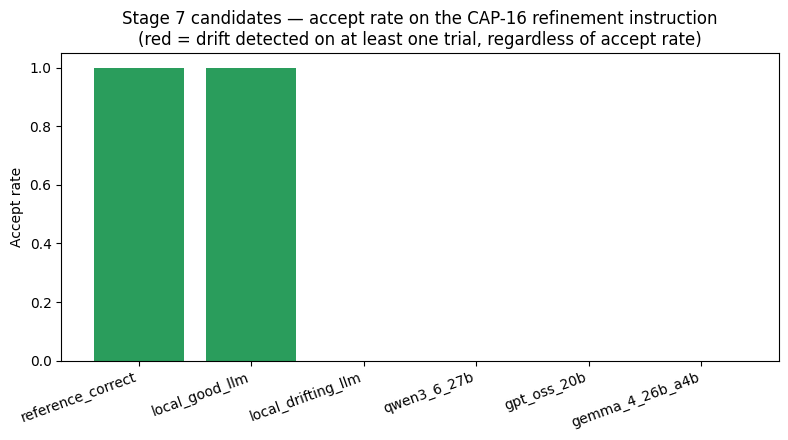

In [10]:
import matplotlib.pyplot as plt

plot_df = summary_df.copy()
# green >= 0.8 and no drift, red if ANY drift was detected regardless of accept
# rate, amber for partial credit with no drift -- drift always overrides color,
# because a drifting model passing "by luck" on other trials should not look safe.
def _bar_color(row):
    if row["drift_detected_count"] > 0:
        return "#d64545"
    if (row["accept_rate"] or 0) >= 0.8:
        return "#2a9d5c"
    if (row["accept_rate"] or 0) > 0:
        return "#e0a63a"
    return "#d64545"

colors = [_bar_color(row) for _, row in plot_df.iterrows()]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(plot_df.index, plot_df["accept_rate"].fillna(0), color=colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accept rate")
ax.set_title("Stage 7 candidates — accept rate on the CAP-16 refinement instruction\n(red = drift detected on at least one trial, regardless of accept rate)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("stage7_comparison.png", dpi=150)
plt.show()

## 7.5 Debug: inspect what a failing model actually generated

The summary table only shows the first failure reason as a one-liner. This
pulls the first failing trial per model (skips models with 0 trials or
where every trial passed) and prints the full generated JSON plus **every**
reason it was rejected — including exactly which parameter drifted, or
exactly which recomputed value was arithmetically wrong.

In [11]:
for name, trials in all_trials.items():
    failing = [t for t in trials if t["verdict"] != "accept"]
    if not failing:
        continue
    worst = failing[0]
    print(f"===== {name} -- trial {worst['trial']} -- verdict: {worst['verdict']} =====")
    print("reasons:")
    for r in worst["reasons"]:
        print(" -", r)
    print()
    if worst["output"] is not None:
        print(json.dumps(worst["output"], indent=2))
    else:
        print("(no output -- generation itself failed, see reasons above)")
    print()

===== local_drifting_llm -- trial 0 -- verdict: reject =====
reasons:
 - resolved_delta has unrequested param(s): ['bore_diameter_mm']
 - DRIFT: parameter(s) modified without being asked: ['bore_diameter_mm']
 - DRIFT: parameter(s) silently dropped from 'unchanged': ['bore_diameter_mm']

{
  "resolved_delta": {
    "pocket_clearance_mm": {
      "from": 0.8,
      "to": 1.1
    },
    "bore_diameter_mm": {
      "from": 50.0,
      "to": 50
    }
  },
  "recomputed": {
    "pocket_radius_mm": {
      "from": 32.8,
      "to": 33.099999999999994
    },
    "web_thickness_mm": {
      "from": 55.36,
      "to": 54.755999649999524
    },
    "outer_diameter_mm": {
      "from": 701.6,
      "to": 702.2
    }
  },
  "unchanged": [
    "pocket_count",
    "pcd_mm",
    "lead_in_chamfer_mm",
    "material_id",
    "plate_thickness_mm",
    "rim_mm"
  ],
  "revalidation": {
    "verdict": "accept",
    "effective_clearance_mm": 0.8
  }
}

===== qwen3_6_27b -- trial 0 -- verdict: skipped =====

## 8. Reading these results

- `reference_correct` and `local_good_llm` should both hit **1.0** -- two
  differently-built, correct implementations of the same edit, proving
  Stage 7 model choice should be judged on the *delta produced*, not
  incidental formatting or code-path differences.
- `local_drifting_llm` should hit **0.0**, with `drift_detected_count = 1`
  -- it computes the requested clearance edit perfectly and still fails,
  because it also silently "tidies up" `bore_diameter_mm`. **This is the
  harness working as intended, not a bug.** A drift failure here is worse
  than a "didn't apply the edit" failure would be: an under-applied edit is
  visibly wrong and gets caught on the shop floor; a drifted untouched
  parameter looks like nothing changed and can reach a machined part. That
  asymmetry is exactly why `drift_detected` is broken out as its own column
  in Section 7 rather than folded into a single pass/fail number.
- `qwen3_6_27b`, `gpt_oss_20b`, and `gemma_4_26b_a4b` are the three real,
  currently-available candidates from the source doc's Stage 1/7 family
  (with the one documented Gemma substitution from Section 2). Their accept
  rate here is the actual answer to "does this model belong in Stage 7" --
  not a demo. Read `drift_detected_count` **before** `accept_rate` for each:
  a model that never drifts but occasionally mis-computes a number is a
  fixable prompt problem; a model that drifts even once is evidence against
  using it unattended, independent of its raw accept rate.
- Because Stage 1 and Stage 7 share one served model in production (per the
  source doc), a real decision should also weigh whichever candidate wins
  the separate Stage 1 harness -- don't pick a Stage 7 winner in isolation
  if it disagrees with the Stage 1 result for the same model family.

For a real production decision, don't stop at one instruction. Loop
Section 6 over a batch of different edit instructions and starting
parameter sets (adds, removes, multi-parameter edits, edits that push a
design into `reject` territory) and compare accept rate and drift rate
across the batch -- one instruction, however many trials, still isn't a
benchmark.

## 9. Running this for real, and what it costs

1. Get an OpenRouter key at openrouter.ai and fund the account (even a $0
   balance triggers HTTP 402, per OpenRouter's docs):
   ```bash
   export OPENROUTER_API_KEY=sk-or-...
   ```
2. Cost per model for 5 trials of this prompt (~450 input + ~250 output
   tokens each, since the response is a small JSON object, not code or
   prose):
   - `qwen3_6_27b` ($0.30/M in, $2.00/M out) — well under a cent for 5 trials
   - `gpt_oss_20b` ($0.03/M in, $0.13/M out) — a small fraction of a cent
   - `gemma_4_26b_a4b` ($0.042/M in, $0.22/M out) — a small fraction of a cent
   All three together, 5 trials each, comes in well under $0.01.
3. To go beyond one example: wrap Section 6 in an outer loop over multiple
   `(starting_params, instruction)` pairs and aggregate `accept_rate` and
   `drift_detected_count` per model across the batch -- that combined
   number, not a single instruction's result, is what should decide which
   model serves Stage 7 (and, per the source doc, Stage 1) in production.
   Good instructions to add: multi-parameter edits in one sentence, edits
   phrased ambiguously enough to need a clarifying question instead of a
   guess, and edits that should legitimately flip `revalidation.verdict`
   to `"reject"`.

## References

- Qwen3.6 27B — model id and pricing: https://openrouter.ai/qwen/qwen3.6-27b · family listing: https://openrouter.ai/qwen
- gpt-oss-20b — model id and pricing: https://openrouter.ai/openai/gpt-oss-20b · family listing: https://openrouter.ai/openai
- Gemma 4 26B A4B (substituted for "Gemma 4 12B") — model id and pricing: https://openrouter.ai/google/gemma-4-26b-a4b-it · family listing: https://openrouter.ai/google
- Gemma 4 31B (the family's other size, considered and not used) — https://openrouter.ai/google/gemma-4-31b-it